# Walmart Data Analysis Notebook
This notebook demonstrates loading Walmart sales data, performing basic inspection, and visualizing key metrics.

In [12]:
import pandas as pd
import numpy as np

df = pd.read_excel(r"C:/Users/ayush/OneDrive/Documents/Desktop/Walmart Data Aanlysis/Data/Amazon2_Raw.xlsx")

print(df.shape)
print(df.head())

(3203, 10)
         Order ID Order Date  Ship Date                   EmailID  \
0  CA-2013-138688 2013-06-13 2013-06-17   DarrinVanHuff@gmail.com   
1  CA-2011-115812 2011-06-09 2011-06-14  BrosinaHoffman@gmail.com   
2  CA-2011-115812 2011-06-09 2011-06-14  BrosinaHoffman@gmail.com   
3  CA-2011-115812 2011-06-09 2011-06-14  BrosinaHoffman@gmail.com   
4  CA-2011-115812 2011-06-09 2011-06-14  BrosinaHoffman@gmail.com   

                              Geography     Category  \
0  United States,Los Angeles,California       Labels   
1  United States,Los Angeles,California  Furnishings   
2  United States,Los Angeles,California          Art   
3  United States,Los Angeles,California       Phones   
4  United States,Los Angeles,California      Binders   

                                        Product Name    Sales  Quantity  \
0  Self-Adhesive Address Labels for Typewriters b...   14.620         2   
1  Eldon Expressions Wood and Plastic Desk Access...   48.860         7   
2           

In [11]:
pip install openpyxl

You should consider upgrading via the 'c:\Users\ayush\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [8]:
import os

path = "C:/Users/ayush/OneDrive/Documents/Desktop/Walmart Data Aanlysis/Data/Amazon2_Raw.xlsx"

print(os.path.exists(path))

True


In [13]:
df.columns.tolist()

['Order ID',
 'Order Date',
 'Ship Date',
 'EmailID',
 'Geography',
 'Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Profit']

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3203 entries, 0 to 3202
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Order ID      3203 non-null   object        
 1   Order Date    3203 non-null   datetime64[ns]
 2   Ship Date     3203 non-null   datetime64[ns]
 3   EmailID       3203 non-null   object        
 4   Geography     3203 non-null   object        
 5   Category      3203 non-null   object        
 6   Product Name  3203 non-null   object        
 7   Sales         3203 non-null   float64       
 8   Quantity      3203 non-null   int64         
 9   Profit        3203 non-null   float64       
dtypes: datetime64[ns](2), float64(2), int64(1), object(5)
memory usage: 250.4+ KB


In [15]:
df.isnull().sum()

Order ID        0
Order Date      0
Ship Date       0
EmailID         0
Geography       0
Category        0
Product Name    0
Sales           0
Quantity        0
Profit          0
dtype: int64

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.describe()

,Order Date,Ship Date,Sales,Quantity,Profit
count,3203,3203,3203.000000,3203.000000,3203.000000
mean,2013-05-10 03:06:07.530440192,2013-05-14 01:25:25.195129600,226.493233,3.828910,33.849032
min,2011-01-07 00:00:00,2011-01-09 00:00:00,0.990000,1.000000,-3399.980000
25%,2012-05-22 00:00:00,2012-05-26 00:00:00,19.440000,2.000000,3.852000
50%,2013-07-22 00:00:00,2013-07-25 00:00:00,60.840000,3.000000,11.166400
75%,2014-05-23 00:00:00,2014-05-27 00:00:00,215.809000,5.000000,33.000400
max,2014-12-31 00:00:00,2015-01-06 00:00:00,13999.960000,14.000000,6719.980800
std,NaN,NaN,524.876877,2.260947,174.109081


In [18]:
print("Unique Orders:", df["Order ID"].nunique())
print("Unique Customers:", df["EmailID"].nunique())
print("Unique Products:", df["Product Name"].nunique())
print("Unique Categories:", df["Category"].nunique())

Unique Orders: 1611
Unique Customers: 686
Unique Products: 1494
Unique Categories: 17


In [19]:
print("Negative Sales:", (df["Sales"] < 0).sum())
print("Zero Sales:", (df["Sales"] == 0).sum())

print("Negative Quantity:", (df["Quantity"] < 0).sum())
print("Zero Quantity:", (df["Quantity"] == 0).sum())

print("Negative Profit:", (df["Profit"] < 0).sum())
print("Zero Profit:", (df["Profit"] == 0).sum())

Negative Sales: 0
Zero Sales: 0
Negative Quantity: 0
Zero Quantity: 0
Negative Profit: 318
Zero Profit: 22


In [20]:
# Create a copy of the original dataset
df_clean = df.copy()

# Shipping duration in days
df_clean["Ship Days"] = (
    df_clean["Ship Date"] - df_clean["Order Date"]
).dt.days

# Date-related features
df_clean["Order Year"] = df_clean["Order Date"].dt.year
df_clean["Order Month"] = df_clean["Order Date"].dt.month
df_clean["Order Month Name"] = df_clean["Order Date"].dt.month_name()
df_clean["Order Quarter"] = df_clean["Order Date"].dt.quarter

# Profit margin
df_clean["Profit Margin"] = (
    df_clean["Profit"] / df_clean["Sales"]
) * 100

# Display the new columns
df_clean[
    [
        "Order Date",
        "Ship Date",
        "Ship Days",
        "Order Year",
        "Order Month",
        "Order Month Name",
        "Order Quarter",
        "Sales",
        "Profit",
        "Profit Margin"
    ]
].head()

,Order Date,Ship Date,Ship Days,Order Year,Order Month,Order Month Name,Order Quarter,Sales,Profit,Profit Margin
0,2013-06-13,2013-06-17,4,2013,6,June,2,14.620,6.8714,47.00
1,2011-06-09,2011-06-14,5,2011,6,June,2,48.860,14.1694,29.00
2,2011-06-09,2011-06-14,5,2011,6,June,2,7.280,1.9656,27.00
3,2011-06-09,2011-06-14,5,2011,6,June,2,907.152,90.7152,10.00
4,2011-06-09,2011-06-14,5,2011,6,June,2,18.504,5.7825,31.25


In [21]:
# Yearly sales and profit
yearly_performance = (
    df_clean
    .groupby("Order Year")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique"),
        Quantity=("Quantity", "sum")
    )
    .reset_index()
)

yearly_performance["Profit Margin"] = (
    yearly_performance["Profit"]
    / yearly_performance["Sales"]
) * 100

yearly_performance


,Order Year,Sales,Profit,Orders,Quantity,Profit Margin
0,2011,147883.0330,20065.6912,313,2531,13.568623
1,2012,139966.2495,20492.1947,338,2438,14.640811
2,2013,186976.0165,23959.9374,419,3010,12.814444
3,2014,250632.5255,43900.6256,541,4285,17.515933


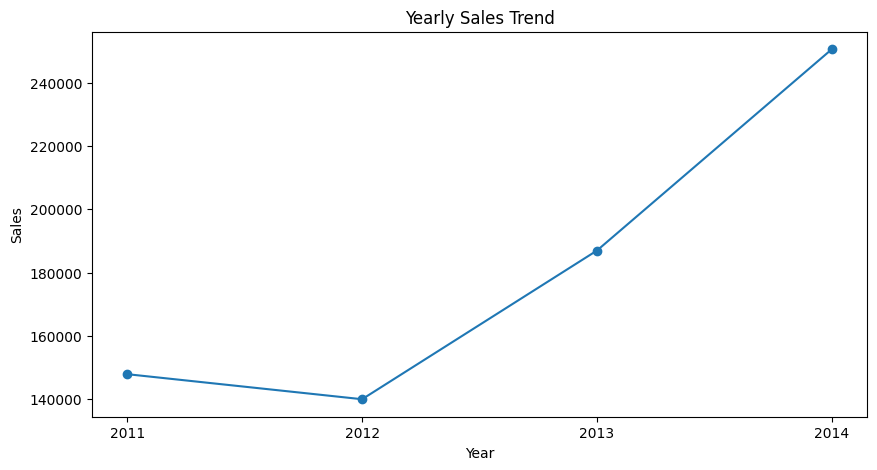

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    yearly_performance["Order Year"],
    yearly_performance["Sales"],
    marker="o"
)

plt.title("Yearly Sales Trend")
plt.xlabel("Year")
plt.ylabel("Sales")
plt.xticks(yearly_performance["Order Year"])

plt.show()

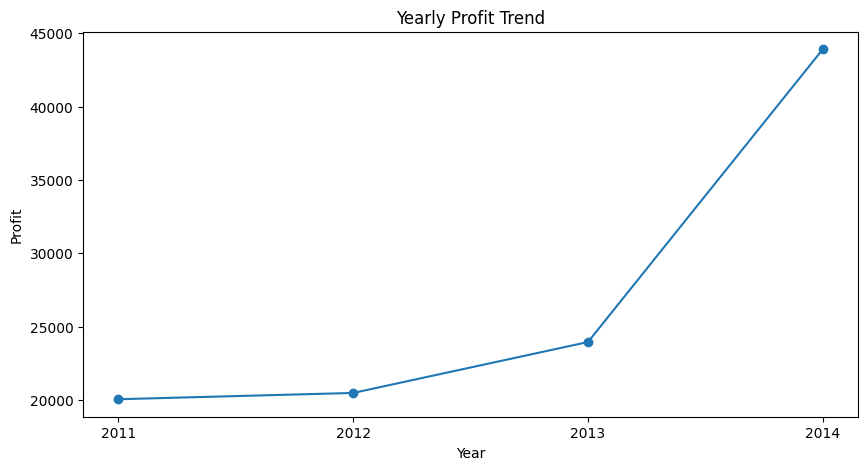

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_performance["Order Year"],
    yearly_performance["Profit"],
    marker="o"
)

plt.title("Yearly Profit Trend")
plt.xlabel("Year")
plt.ylabel("Profit")
plt.xticks(yearly_performance["Order Year"])

plt.show()

In [24]:
category_performance = (
    df_clean
    .groupby("Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique"),
        Quantity=("Quantity", "sum")
    )
    .reset_index()
)

category_performance["Profit Margin"] = (
    category_performance["Profit"]
    / category_performance["Sales"]
) * 100

category_performance = category_performance.sort_values(
    "Sales",
    ascending=False
)

category_performance

,Category,Sales,Profit,Orders,Quantity,Profit Margin
5,Chairs,101781.3280,4027.5843,191,734,3.957095
13,Phones,98684.3520,9110.7426,256,1066,9.232206
16,Tables,84754.5620,1482.6073,114,481,1.749295
14,Storage,70532.8520,8645.3222,247,1039,12.257157
0,Accessories,61114.1160,16484.5983,236,1032,26.973471
3,Binders,55961.1130,16096.8016,403,1868,28.764263
6,Copiers,49749.2420,19327.2351,25,88,38.849306
11,Machines,42444.1220,-618.9264,39,147,-1.458215
4,Bookcases,36004.1235,-1646.5117,79,306,-4.573120
1,Appliances,30236.3360,8261.2699,134,492,27.322325


In [25]:
category_performance.sort_values(
    "Profit",
    ascending=False
).head(10)

,Category,Sales,Profit,Orders,Quantity,Profit Margin
6,Copiers,49749.242,19327.2351,25,88,38.849306
0,Accessories,61114.116,16484.5983,236,1032,26.973471
3,Binders,55961.113,16096.8016,403,1868,28.764263
12,Paper,26663.718,12119.2364,384,1702,45.452162
13,Phones,98684.352,9110.7426,256,1066,9.232206
14,Storage,70532.852,8645.3222,247,1039,12.257157
1,Appliances,30236.336,8261.2699,134,492,27.322325
9,Furnishings,30072.730,7641.2704,281,1175,25.409301
5,Chairs,101781.328,4027.5843,191,734,3.957095
2,Art,9212.066,2374.0970,227,926,25.771602


In [26]:
category_performance.sort_values(
    "Profit",
    ascending=True
).head(10)

,Category,Sales,Profit,Orders,Quantity,Profit Margin
4,Bookcases,36004.1235,-1646.5117,79,306,-4.573120
11,Machines,42444.1220,-618.9264,39,147,-1.458215
8,Fasteners,923.2160,275.1907,72,263,29.807835
15,Supplies,18127.1220,626.0465,68,238,3.453645
16,Tables,84754.5620,1482.6073,114,481,1.749295
7,Envelopes,4118.1000,1908.7624,66,227,46.350560
10,Labels,5078.7260,2303.1223,112,480,45.348426
2,Art,9212.0660,2374.0970,227,926,25.771602
5,Chairs,101781.3280,4027.5843,191,734,3.957095
9,Furnishings,30072.7300,7641.2704,281,1175,25.409301


In [27]:
category_performance.sort_values(
    "Profit Margin",
    ascending=True
)

,Category,Sales,Profit,Orders,Quantity,Profit Margin
4,Bookcases,36004.1235,-1646.5117,79,306,-4.573120
11,Machines,42444.1220,-618.9264,39,147,-1.458215
16,Tables,84754.5620,1482.6073,114,481,1.749295
15,Supplies,18127.1220,626.0465,68,238,3.453645
5,Chairs,101781.3280,4027.5843,191,734,3.957095
13,Phones,98684.3520,9110.7426,256,1066,9.232206
14,Storage,70532.8520,8645.3222,247,1039,12.257157
9,Furnishings,30072.7300,7641.2704,281,1175,25.409301
2,Art,9212.0660,2374.0970,227,926,25.771602
0,Accessories,61114.1160,16484.5983,236,1032,26.973471


In [29]:
product_performance = (
    df_clean
    .groupby("Product Name")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"),
        Orders=("Order ID", "nunique")
    )
    .reset_index()
)

product_performance["Profit Margin"] = (
    product_performance["Profit"]
    / product_performance["Sales"]
) * 100


In [30]:
product_performance.sort_values(
    "Sales",
    ascending=False
).head(10)

,Product Name,Sales,Profit,Quantity,Orders,Profit Margin
328,Canon imageCLASS 2200 Advanced Copier,13999.960,6719.9808,4,1,48.000000
661,High Speed Automatic Electric Letter Opener,13100.240,524.0096,8,2,4.000000
627,Global Troy Executive Leather Low-Back Tilter,10019.600,626.2250,25,7,6.250000
524,Fellowes PB500 Electric Punch Plastic Comb Bin...,8134.336,3050.3760,8,3,37.500000
642,GuestStacker Chair with Chrome Finish Legs,8030.016,803.0016,27,6,10.000000
990,Okidata MB760 Printer,7834.400,881.3700,7,2,11.250000
299,Bretford Rectangular Conference Table Tops,7710.665,180.5424,26,7,2.341463
829,LogitechÂ P710e Mobile Speakerphone,7467.210,1418.7699,29,5,19.000000
325,Canon PC1060 Personal Laser Copier,6719.904,2267.9676,12,3,33.750000
659,Hewlett Packard LaserJet 3310 Copier,6239.896,2183.9636,13,3,35.000000


In [31]:
product_performance.sort_values(
    "Profit",
    ascending=False
).head(10)

,Product Name,Sales,Profit,Quantity,Orders,Profit Margin
328,Canon imageCLASS 2200 Advanced Copier,13999.960,6719.9808,4,1,48.00
524,Fellowes PB500 Electric Punch Plastic Comb Bin...,8134.336,3050.3760,8,3,37.50
325,Canon PC1060 Personal Laser Copier,6719.904,2267.9676,12,3,33.75
659,Hewlett Packard LaserJet 3310 Copier,6239.896,2183.9636,13,3,35.00
831,LogitechÂ Z-906 Speaker sys - home theater - 5...,4289.870,1715.9480,13,3,40.00
1041,Plantronics Savi W720 Multi-Device Wireless He...,3797.550,1670.9220,9,3,44.00
725,Ibico EPK-21 Electric Binding System,4535.976,1644.2913,3,1,36.25
327,Canon PC940 Copier,3149.930,1480.4671,7,1,47.00
829,LogitechÂ P710e Mobile Speakerphone,7467.210,1418.7699,29,5,19.00
322,Canon Image Class D660 Copier,2999.950,1379.9770,5,1,46.00


In [32]:
product_performance.sort_values(
    "Profit",
    ascending=True
).head(10)

,Product Name,Sales,Profit,Quantity,Orders,Profit Margin
793,Lexmark MX611dhe Monochrome Laser Printer,2549.985,-3399.9800,5,1,-133.333333
1483,Zebra GK420t Direct Thermal/Thermal Transfer P...,703.710,-938.2800,6,1,-133.333333
960,O'Sullivan 4-Shelf Bookcase in Odessa Pine,1808.651,-802.0974,26,4,-44.347826
670,Hon 2090 Â“Pillow SoftÂ” Series Mid Back Swive...,3371.760,-547.9110,15,4,-16.250000
139,"Atlantic Metals Mobile 4-Shelf Bookcases, Cust...",2261.889,-491.7150,14,3,-21.739130
259,Bestar Classic Bookcase,1179.882,-439.9560,20,5,-37.288136
345,"Chromcraft 48"" x 96"" Racetrack Double Pedestal...",1314.624,-436.0704,7,2,-33.170732
300,Bretford Â“Just In TimeÂ” Height-Adjustable Mu...,5008.800,-425.7480,14,3,-8.500000
552,GBC DocuBind 300 Electric Binding Machine,1788.332,-399.7448,8,2,-22.352941
1003,Panasonic KX MC6040 Color Laser Multifunction ...,269.970,-386.9570,2,1,-143.333333


In [33]:
loss_products = product_performance[
    product_performance["Profit"] < 0
].sort_values("Profit")

loss_products.head(20)

,Product Name,Sales,Profit,Quantity,Orders,Profit Margin
793,Lexmark MX611dhe Monochrome Laser Printer,2549.985,-3399.9800,5,1,-133.333333
1483,Zebra GK420t Direct Thermal/Thermal Transfer P...,703.710,-938.2800,6,1,-133.333333
960,O'Sullivan 4-Shelf Bookcase in Odessa Pine,1808.651,-802.0974,26,4,-44.347826
670,Hon 2090 Â“Pillow SoftÂ” Series Mid Back Swive...,3371.760,-547.9110,15,4,-16.250000
139,"Atlantic Metals Mobile 4-Shelf Bookcases, Cust...",2261.889,-491.7150,14,3,-21.739130
259,Bestar Classic Bookcase,1179.882,-439.9560,20,5,-37.288136
345,"Chromcraft 48"" x 96"" Racetrack Double Pedestal...",1314.624,-436.0704,7,2,-33.170732
300,Bretford Â“Just In TimeÂ” Height-Adjustable Mu...,5008.800,-425.7480,14,3,-8.500000
552,GBC DocuBind 300 Electric Binding Machine,1788.332,-399.7448,8,2,-22.352941
1003,Panasonic KX MC6040 Color Laser Multifunction ...,269.970,-386.9570,2,1,-143.333333


In [34]:
df_clean[
    df_clean["Product Name"].str.contains(
        "Lexmark MX611dhe",
        case=False,
        na=False
    )
]

,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit,Ship Days,Order Year,Order Month,Order Month Name,Order Quarter,Profit Margin
969,CA-2014-134845,2014-04-18,2014-04-24,SharelleRoach@gmail.com,"United States,Louisville,Colorado",Machines,Lexmark MX611dhe Monochrome Laser Printer,2549.985,5,-3399.98,6,2014,4,April,2,-133.333333


In [35]:
snapshot = df_clean["Order Date"].max() + pd.Timedelta(days=1)

rfm = (
    df_clean.groupby("EmailID")
    .agg(
        Recency=("Order Date",
                 lambda x: (snapshot - x.max()).days),
        Frequency=("Order ID", "nunique"),
        Monetary=("Sales", "sum")
    )
)

rfm.head()

,Recency,Frequency,Monetary
EmailID,,,
AaronBergman@gmail.com,1396,1,309.592
AaronHawkins@gmail.com,735,3,1328.124
AaronSmayling@gmail.com,89,3,737.028
AdamBellavance@gmail.com,55,3,2693.918
AdamHart@gmail.com,260,3,463.770


In [36]:
# Create RFM scores
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"],
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

rfm.head()


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
EmailID,,,,,,,
AaronBergman@gmail.com,1396,1,309.592,1,1,2,112
AaronHawkins@gmail.com,735,3,1328.124,1,4,4,144
AaronSmayling@gmail.com,89,3,737.028,4,4,3,443
AdamBellavance@gmail.com,55,3,2693.918,5,4,5,545
AdamHart@gmail.com,260,3,463.770,3,4,3,343


In [37]:
rfm["Frequency"].rank(method="first")

EmailID
AaronBergman@gmail.com           1.0
AaronHawkins@gmail.com         413.0
AaronSmayling@gmail.com        414.0
AdamBellavance@gmail.com       415.0
AdamHart@gmail.com             416.0
                               ...  
XylonaPreis@gmail.com          643.0
YanaSorensen@gmail.com         644.0
YosephCarroll@gmail.com        411.0
ZuschussCarroll@gmail.com      675.0
ZuschussDonatelli@gmail.com    412.0
Name: Frequency, Length: 686, dtype: float64

In [38]:
def segment_customer(row):
    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    
    elif r >= 3 and f >= 4:
        return "Loyal Customers"
    
    elif r >= 4 and f <= 2:
        return "New / Potential Customers"
    
    elif r <= 2 and f >= 3 and m >= 3:
        return "At Risk"
    
    elif r <= 2 and f <= 2:
        return "Lost Customers"
    
    else:
        return "Regular Customers"


rfm["Segment"] = rfm.apply(segment_customer, axis=1)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
EmailID,,,,,,,,
AaronBergman@gmail.com,1396,1,309.592,1,1,2,112,Lost Customers
AaronHawkins@gmail.com,735,3,1328.124,1,4,4,144,At Risk
AaronSmayling@gmail.com,89,3,737.028,4,4,3,443,Loyal Customers
AdamBellavance@gmail.com,55,3,2693.918,5,4,5,545,Champions
AdamHart@gmail.com,260,3,463.770,3,4,3,343,Loyal Customers


In [39]:
segment_summary = (
    rfm["Segment"]
    .value_counts()
    .reset_index()
)

segment_summary.columns = ["Segment", "Customers"]

segment_summary

,Segment,Customers
0,Lost Customers,166
1,Regular Customers,162
2,Loyal Customers,126
3,Champions,90
4,At Risk,73
5,New / Potential Customers,69


In [40]:
segment_summary["Customer %"] = (
    segment_summary["Customers"]
    / segment_summary["Customers"].sum()
) * 100

segment_summary

,Segment,Customers,Customer %
0,Lost Customers,166,24.198251
1,Regular Customers,162,23.615160
2,Loyal Customers,126,18.367347
3,Champions,90,13.119534
4,At Risk,73,10.641399
5,New / Potential Customers,69,10.058309


In [41]:
segment_value = (
    rfm.groupby("Segment")
    .agg(
        Customers=("Monetary", "count"),
        Revenue=("Monetary", "sum"),
        Avg_Customer_Value=("Monetary", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Recency=("Recency", "mean")
    )
    .reset_index()
    .sort_values("Revenue", ascending=False)
)

segment_value

,Segment,Customers,Revenue,Avg_Customer_Value,Avg_Frequency,Avg_Recency
1,Champions,90,214186.9100,2379.854556,3.922222,72.622222
5,Regular Customers,162,141517.3600,873.563951,1.907407,282.623457
3,Loyal Customers,126,129961.7445,1031.442417,3.587302,162.722222
0,At Risk,73,122849.2455,1682.866377,2.876712,596.397260
2,Lost Customers,166,74306.8355,447.631539,1.180723,836.921687
4,New / Potential Customers,69,42635.7290,617.909116,1.318841,75.811594


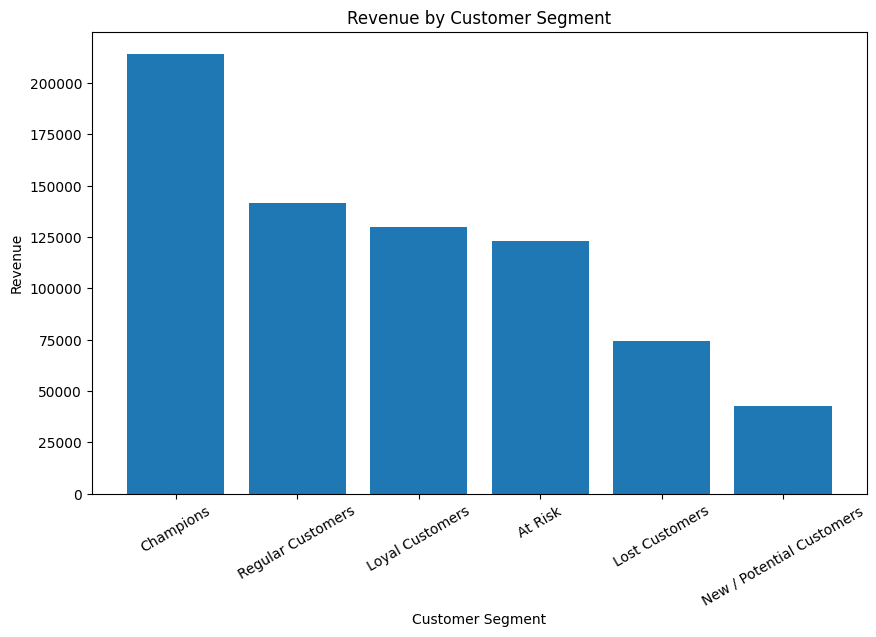

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    segment_value["Segment"],
    segment_value["Revenue"]
)

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue")
plt.xticks(rotation=30)

plt.show()


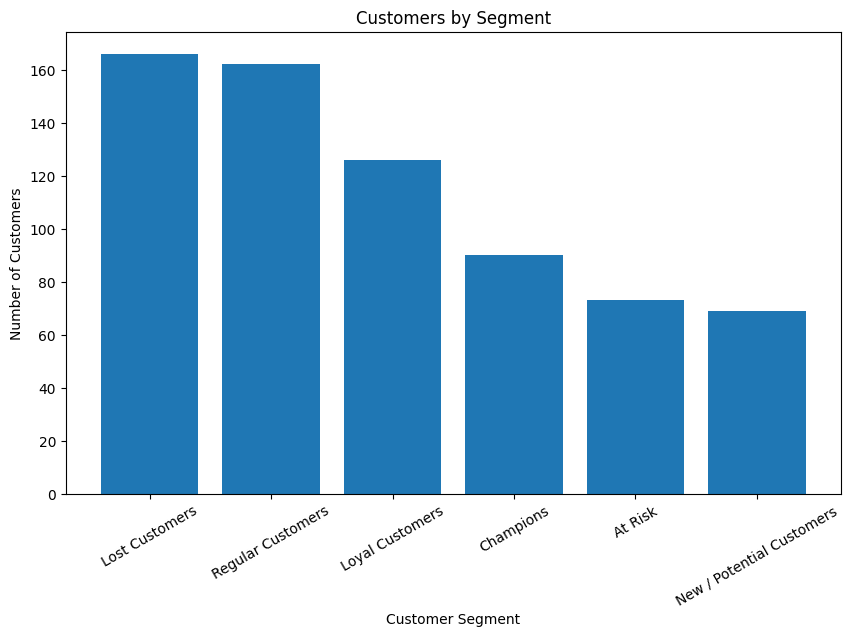

In [43]:
plt.figure(figsize=(10, 6))

plt.bar(
    segment_summary["Segment"],
    segment_summary["Customers"]
)

plt.title("Customers by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

plt.show()

In [44]:
customer_activity = (
    df_clean.groupby("EmailID")
    .agg(
        First_Order=("Order Date", "min"),
        Last_Order=("Order Date", "max"),
        Orders=("Order ID", "nunique"),
        Revenue=("Sales", "sum")
    )
    .reset_index()
)

customer_activity["Customer_Lifetime_Days"] = (
    customer_activity["Last_Order"]
    - customer_activity["First_Order"]
).dt.days

customer_activity.head()

,EmailID,First_Order,Last_Order,Orders,Revenue,Customer_Lifetime_Days
0,AaronBergman@gmail.com,2011-03-07,2011-03-07,1,309.592,0
1,AaronHawkins@gmail.com,2011-05-13,2012-12-27,3,1328.124,594
2,AaronSmayling@gmail.com,2013-09-26,2014-10-04,3,737.028,373
3,AdamBellavance@gmail.com,2012-09-18,2014-11-07,3,2693.918,780
4,AdamHart@gmail.com,2011-11-16,2014-04-16,3,463.770,882


In [45]:
analysis_date = df_clean["Order Date"].max() + pd.Timedelta(days=1)

customer_activity["Days_Since_Last_Order"] = (
    analysis_date - customer_activity["Last_Order"]
).dt.days

customer_activity["Inactive"] = (
    customer_activity["Days_Since_Last_Order"] >= 180
)

customer_activity.head()

,EmailID,First_Order,Last_Order,Orders,Revenue,Customer_Lifetime_Days,Days_Since_Last_Order,Inactive
0,AaronBergman@gmail.com,2011-03-07,2011-03-07,1,309.592,0,1396,True
1,AaronHawkins@gmail.com,2011-05-13,2012-12-27,3,1328.124,594,735,True
2,AaronSmayling@gmail.com,2013-09-26,2014-10-04,3,737.028,373,89,False
3,AdamBellavance@gmail.com,2012-09-18,2014-11-07,3,2693.918,780,55,False
4,AdamHart@gmail.com,2011-11-16,2014-04-16,3,463.770,882,260,True


In [46]:
analysis_date = df_clean["Order Date"].max() + pd.Timedelta(days=1)

customer_activity["Days_Since_Last_Order"] = (
    analysis_date - customer_activity["Last_Order"]
).dt.days

customer_activity["Inactive"] = (
    customer_activity["Days_Since_Last_Order"] >= 180
)

customer_activity.head()

,EmailID,First_Order,Last_Order,Orders,Revenue,Customer_Lifetime_Days,Days_Since_Last_Order,Inactive
0,AaronBergman@gmail.com,2011-03-07,2011-03-07,1,309.592,0,1396,True
1,AaronHawkins@gmail.com,2011-05-13,2012-12-27,3,1328.124,594,735,True
2,AaronSmayling@gmail.com,2013-09-26,2014-10-04,3,737.028,373,89,False
3,AdamBellavance@gmail.com,2012-09-18,2014-11-07,3,2693.918,780,55,False
4,AdamHart@gmail.com,2011-11-16,2014-04-16,3,463.770,882,260,True


In [47]:
inactive_customers = customer_activity[
    customer_activity["Inactive"]
]

revenue_at_risk = inactive_customers["Revenue"].sum()

print("Revenue at Risk: $", round(revenue_at_risk, 2))

Revenue at Risk: $ 377975.81


In [48]:
inactive_customers.sort_values(
    "Revenue",
    ascending=False
).head(20)

,EmailID,First_Order,Last_Order,Orders,Revenue,Customer_Lifetime_Days,Days_Since_Last_Order,Inactive
539,RaymondBuch@gmail.com,2013-07-15,2014-03-24,2,14345.2760,252,283,True
214,EdwardHooks@gmail.com,2011-04-12,2013-12-24,5,7447.7700,987,373,True
146,ClayLudtke@gmail.com,2011-07-12,2014-03-18,5,6069.6440,980,289,True
680,WilliamBrown@gmail.com,2011-11-04,2014-06-30,5,5523.0540,969,185,True
194,DennisPardue@gmail.com,2011-07-05,2013-10-22,3,4941.6760,840,436,True
452,MaxJones@gmail.com,2013-06-25,2013-11-08,3,4909.7100,136,419,True
430,MaribethSchnelling@gmail.com,2012-12-24,2014-04-02,4,4468.3380,464,274,True
10,AlanDominguez@gmail.com,2014-01-23,2014-05-01,2,4353.3400,98,245,True
323,JimKriz@gmail.com,2011-09-19,2014-07-04,3,4267.1700,1019,181,True
548,RickHuthwaite@gmail.com,2012-08-31,2013-07-16,4,4160.1000,319,534,True


In [49]:
print("Revenue at Risk: $", round(revenue_at_risk, 2))

Revenue at Risk: $ 377975.81


In [50]:
print("Total Customers:", customer_activity["EmailID"].nunique())

print(
    "Inactive Customers:",
    customer_activity["Inactive"].sum()
)

print(
    "Inactive Rate:",
    round(customer_activity["Inactive"].mean() * 100, 2),
    "%"
)


Total Customers: 686
Inactive Customers: 406
Inactive Rate: 59.18 %


In [51]:
rfm_retention = rfm[[
    "Segment",
    "Monetary",
    "Frequency",
    "Recency"
]].copy()

rfm_retention["Inactive"] = rfm_retention["Recency"] >= 180

segment_churn = (
    rfm_retention
    .groupby("Segment")
    .agg(
        Customers=("Inactive", "count"),
        Inactive_Customers=("Inactive", "sum"),
        Revenue=("Monetary", "sum")
    )
    .reset_index()
)

segment_churn["Inactive Rate"] = (
    segment_churn["Inactive_Customers"]
    / segment_churn["Customers"]
) * 100

segment_churn.sort_values(
    "Inactive Rate",
    ascending=False
)


,Segment,Customers,Inactive_Customers,Revenue,Inactive Rate
0,At Risk,73,73,122849.2455,100.000000
2,Lost Customers,166,166,74306.8355,100.000000
5,Regular Customers,162,109,141517.3600,67.283951
3,Loyal Customers,126,58,129961.7445,46.031746
1,Champions,90,0,214186.9100,0.000000
4,New / Potential Customers,69,0,42635.7290,0.000000


In [52]:
customer_geo = (
    df_clean
    .groupby("EmailID")
    .agg(
        Geography=("Geography", "first"),
        Revenue=("Sales", "sum"),
        Orders=("Order ID", "nunique"),
        Last_Order=("Order Date", "max")
    )
    .reset_index()
)

customer_geo["Days_Since_Last_Order"] = (
    analysis_date - customer_geo["Last_Order"]
).dt.days

customer_geo["Inactive"] = (
    customer_geo["Days_Since_Last_Order"] >= 180
)

In [53]:
geo_retention = (
    customer_geo
    .groupby("Geography")
    .agg(
        Customers=("EmailID", "count"),
        Inactive_Customers=("Inactive", "sum"),
        Revenue=("Revenue", "sum")
    )
    .reset_index()
)

geo_retention["Inactive Rate"] = (
    geo_retention["Inactive_Customers"]
    / geo_retention["Customers"]
) * 100

geo_retention.sort_values(
    "Inactive Rate",
    ascending=False
)

,Geography,Customers,Inactive_Customers,Revenue,Inactive Rate
7,"United States,Bakersfield,California",1,1,19.152,100.0
5,"United States,Auburn,Washington",1,1,4.180,100.0
20,"United States,Covington,Washington",1,1,702.290,100.0
24,"United States,El Cajon,California",1,1,387.136,100.0
23,"United States,Edmonds,Washington",1,1,143.240,100.0
...,...,...,...,...,...
109,"United States,Tempe,Arizona",1,0,695.640,0.0
116,"United States,Vancouver,Washington",2,0,10801.988,0.0
118,"United States,Westminster,California",1,0,2563.314,0.0
119,"United States,Whittier,California",1,0,444.768,0.0


In [54]:
high_value_inactive = customer_geo[
    customer_geo["Inactive"]
].sort_values(
    "Revenue",
    ascending=False
)

high_value_inactive.head(20)

,EmailID,Geography,Revenue,Orders,Last_Order,Days_Since_Last_Order,Inactive
539,RaymondBuch@gmail.com,"United States,San Francisco,California",14345.2760,2,2014-03-24,283,True
214,EdwardHooks@gmail.com,"United States,Seattle,Washington",7447.7700,5,2013-12-24,373,True
146,ClayLudtke@gmail.com,"United States,Lancaster,California",6069.6440,5,2014-03-18,289,True
680,WilliamBrown@gmail.com,"United States,Concord,California",5523.0540,5,2014-06-30,185,True
194,DennisPardue@gmail.com,"United States,San Francisco,California",4941.6760,3,2013-10-22,436,True
452,MaxJones@gmail.com,"United States,Seattle,Washington",4909.7100,3,2013-11-08,419,True
430,MaribethSchnelling@gmail.com,"United States,Phoenix,Arizona",4468.3380,4,2014-04-02,274,True
10,AlanDominguez@gmail.com,"United States,Great Falls,Montana",4353.3400,2,2014-05-01,245,True
323,JimKriz@gmail.com,"United States,Seattle,Washington",4267.1700,3,2014-07-04,181,True
548,RickHuthwaite@gmail.com,"United States,Provo,Utah",4160.1000,4,2013-07-16,534,True


In [55]:
df_clean.to_csv(
    r"C:\Users\ayush\OneDrive\Documents\Desktop\Walmart Data Aanlysis\Data\walmart_cleaned.csv",
    index=False
)

In [56]:
import os

path = r"C:\Users\ayush\OneDrive\Documents\Desktop\Walmart Data Aanlysis\Data\walmart_cleaned.csv"

print(os.path.exists(path))

True


In [57]:
import pandas as pd

csv_path = r"C:\Users\ayush\OneDrive\Documents\Desktop\Walmart Data Aanlysis\Data\walmart_cleaned.csv"

test_df = pd.read_csv(csv_path)

print("Rows:", len(test_df))
print("Columns:", len(test_df.columns))

Rows: 3203
Columns: 16
